# Segmenting and Counting Nuclei in Bioimages

The task is to do the following (from the presentation by Mario del Rosario): "Create a reproducible mask, count nuclei, and
explain one limitation."

The steps are as follow:
Choose Fiji or Python
- FIJI can be downloaded from https://fiji.sc
- Use any image from the BBBC039 repositor: https://bbbc.broadinstitute.org/BBBC039
- Record threshold and cleanup settings
- Include an overlay on the original image
- Report count and median object area
- Describe one visible segmentation error

I chose to use Python due to being somewhat familiar with it after some courses from UTU. Using some of the more known packages in scientific workflows for Python (e.g. `numpy`, `pandas`, `matplotlib`, `scipy` and `scikit-image`), I managed to get decent results. Due to my limited knowledge in the field of biology, some of the results might be more difficult to confirm. However, using a relatively primitive validation method called taking a look, I think the results from this rather small project are alright and show that the correct idea is applied.
## Imports and getting data

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import ndimage as ndi
from skimage import measure
from skimage.feature import peak_local_max
from skimage.filters import (
    threshold_isodata,
    threshold_li,
    threshold_otsu,
    threshold_yen,
    try_all_threshold,
)
from skimage.morphology import closing, disk, remove_small_holes, remove_small_objects
from skimage.segmentation import watershed

## Methods

I chose at random three images from the image dataset and set them aside in the data folder. The rest of the images can still be found in the images folder and could (in theory) simply be moved one directory up and they would automatically be analysed using this script.

Found file: images
Found file: IXMtest_A24_s9_w152CD6793-DA45-4975-869A-CBD49D645E37.tif
Found file: IXMtest_C02_s4_w1661FF37C-AB9B-4038-BDF3-D21DFD2811BE.tif
Found file: IXMtest_O01_s6_w11A23978B-BAAD-4287-B1F6-FFBCF45C5E2F.tif
Found file: IXMtest_P13_s6_w1270AEE06-D31F-421C-8147-13644F4C5B94.tif
Image shape: (520, 696)
Image dtype: uint16


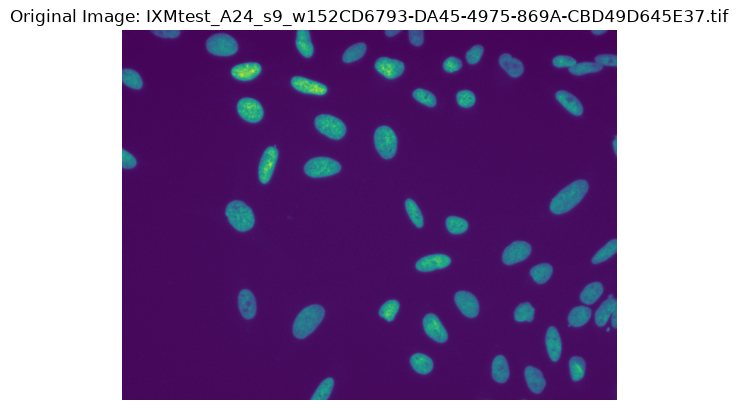

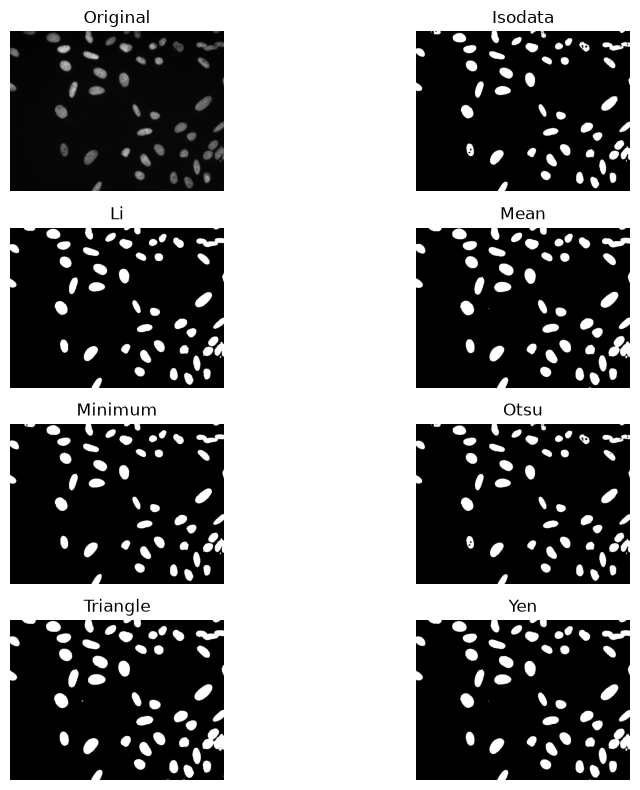

Image shape: (520, 696)
Image dtype: uint16


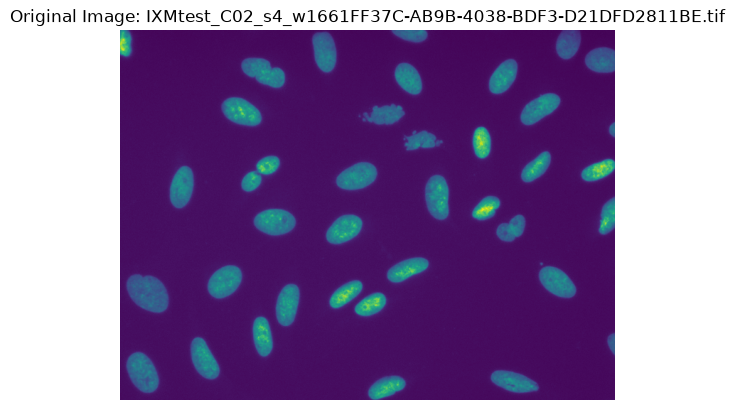

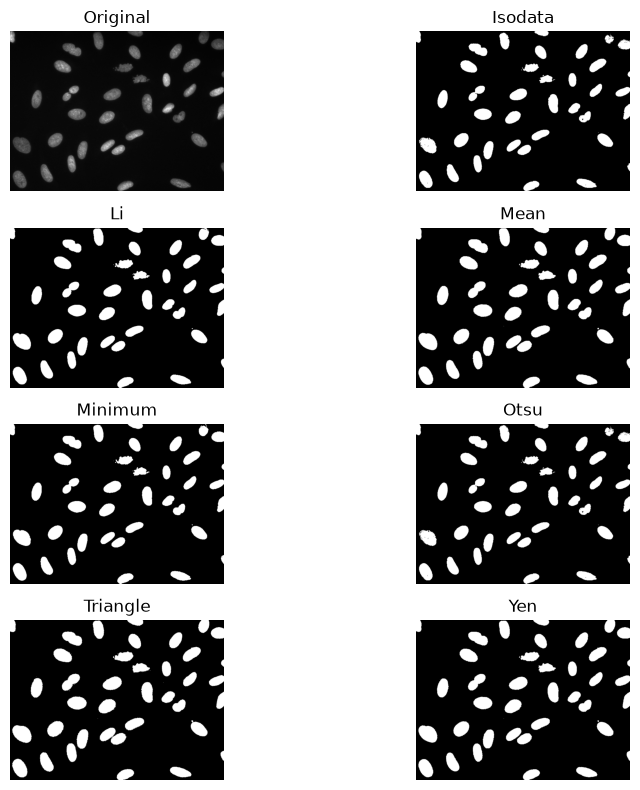

Image shape: (520, 696)
Image dtype: uint16


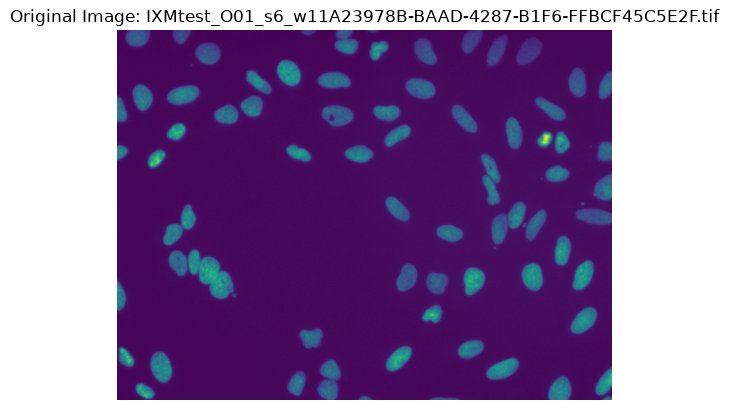

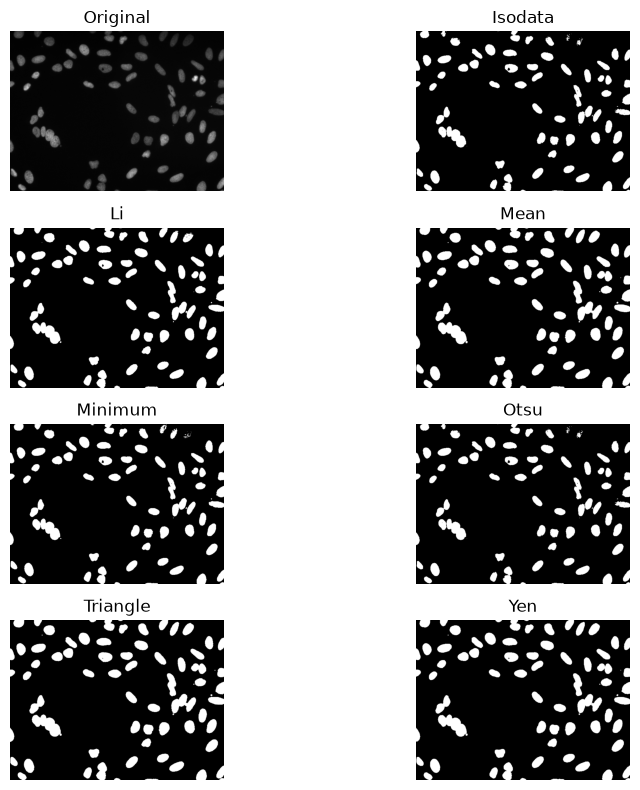

Image shape: (520, 696)
Image dtype: uint16


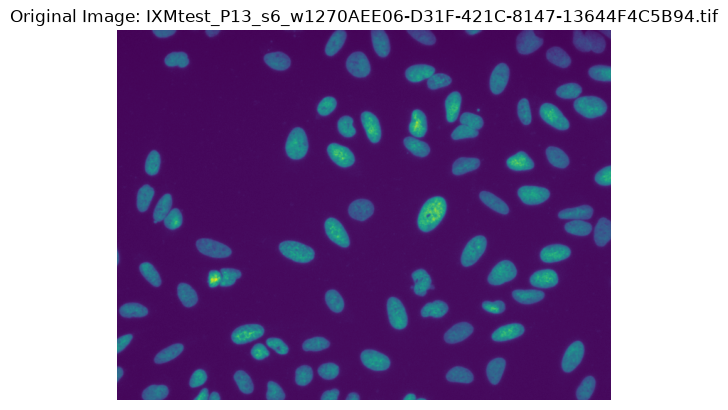

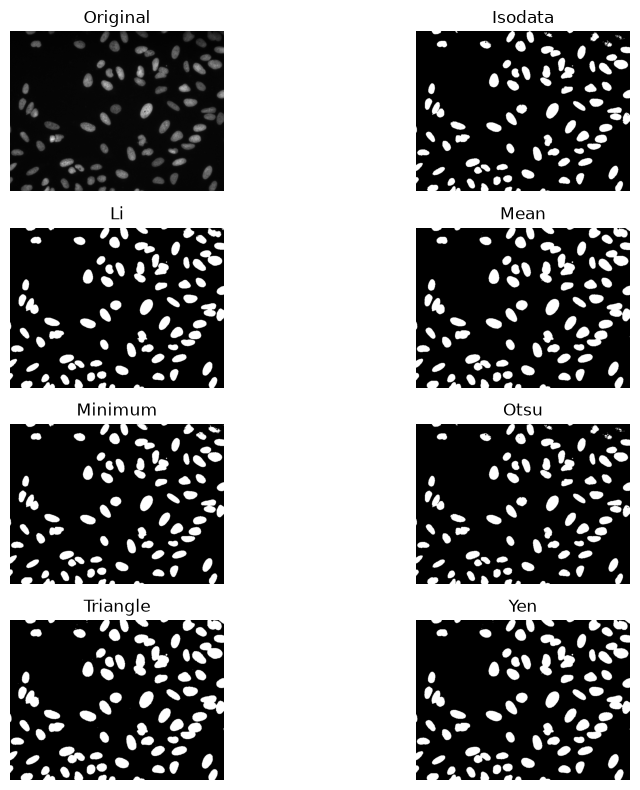

In [2]:
data_dir = os.path.join(os.getcwd(), "data")
for file in os.listdir(data_dir):
    print("Found file:", file)
    
files = [f for f in os.listdir(data_dir) if f.endswith(('.tiff', '.tif'))]

for file in files:
    image_path = os.path.join(data_dir, file)
    image = plt.imread(image_path)
    print(f"Image shape: {image.shape}")
    print(f"Image dtype: {image.dtype}")
    plt.imshow(image)
    plt.title(f"Original Image: {file}")
    
    plt.axis('off')
    plt.show()
    
    fig, ax = try_all_threshold(image, figsize=(10, 8), verbose=False)
    plt.show()

## Analysis

No clear preferred thresholding method. Selecting three quite common methods used in UTU for courses: Otsu, Li, Yen and Isodata. 

,image,method,threshold,min_object_area,min_hole_area,closing_radius,count,median_object_area,split_count,split_median_object_area,watershed_min_distance
0,IXMtest_A24_s9_w152CD6793-DA45-4975-869A-CBD49...,otsu,410.000000,50,50,1,48,719.5,50,702.5,14
1,IXMtest_A24_s9_w152CD6793-DA45-4975-869A-CBD49...,li,301.674506,50,50,1,48,784.0,51,776.0,14
2,IXMtest_A24_s9_w152CD6793-DA45-4975-869A-CBD49...,yen,213.000000,50,50,1,46,911.0,51,885.0,14
3,IXMtest_A24_s9_w152CD6793-DA45-4975-869A-CBD49...,isodata,410.000000,50,50,1,48,719.5,50,702.5,14
4,IXMtest_C02_s4_w1661FF37C-AB9B-4038-BDF3-D21DF...,otsu,325.000000,50,50,1,38,1224.5,40,1107.5,14
5,IXMtest_C02_s4_w1661FF37C-AB9B-4038-BDF3-D21DF...,li,254.987253,50,50,1,38,1313.5,40,1238.5,14
6,IXMtest_C02_s4_w1661FF37C-AB9B-4038-BDF3-D21DF...,yen,196.000000,50,50,1,38,1460.5,41,1339.0,14
7,IXMtest_C02_s4_w1661FF37C-AB9B-4038-BDF3-D21DF...,isodata,325.000000,50,50,1,38,1224.5,40,1107.5,14
8,IXMtest_O01_s6_w11A23978B-BAAD-4287-B1F6-FFBCF...,otsu,348.000000,50,50,1,65,644.0,74,618.0,14
9,IXMtest_O01_s6_w11A23978B-BAAD-4287-B1F6-FFBCF...,li,260.821536,50,50,1,68,735.5,76,708.0,14


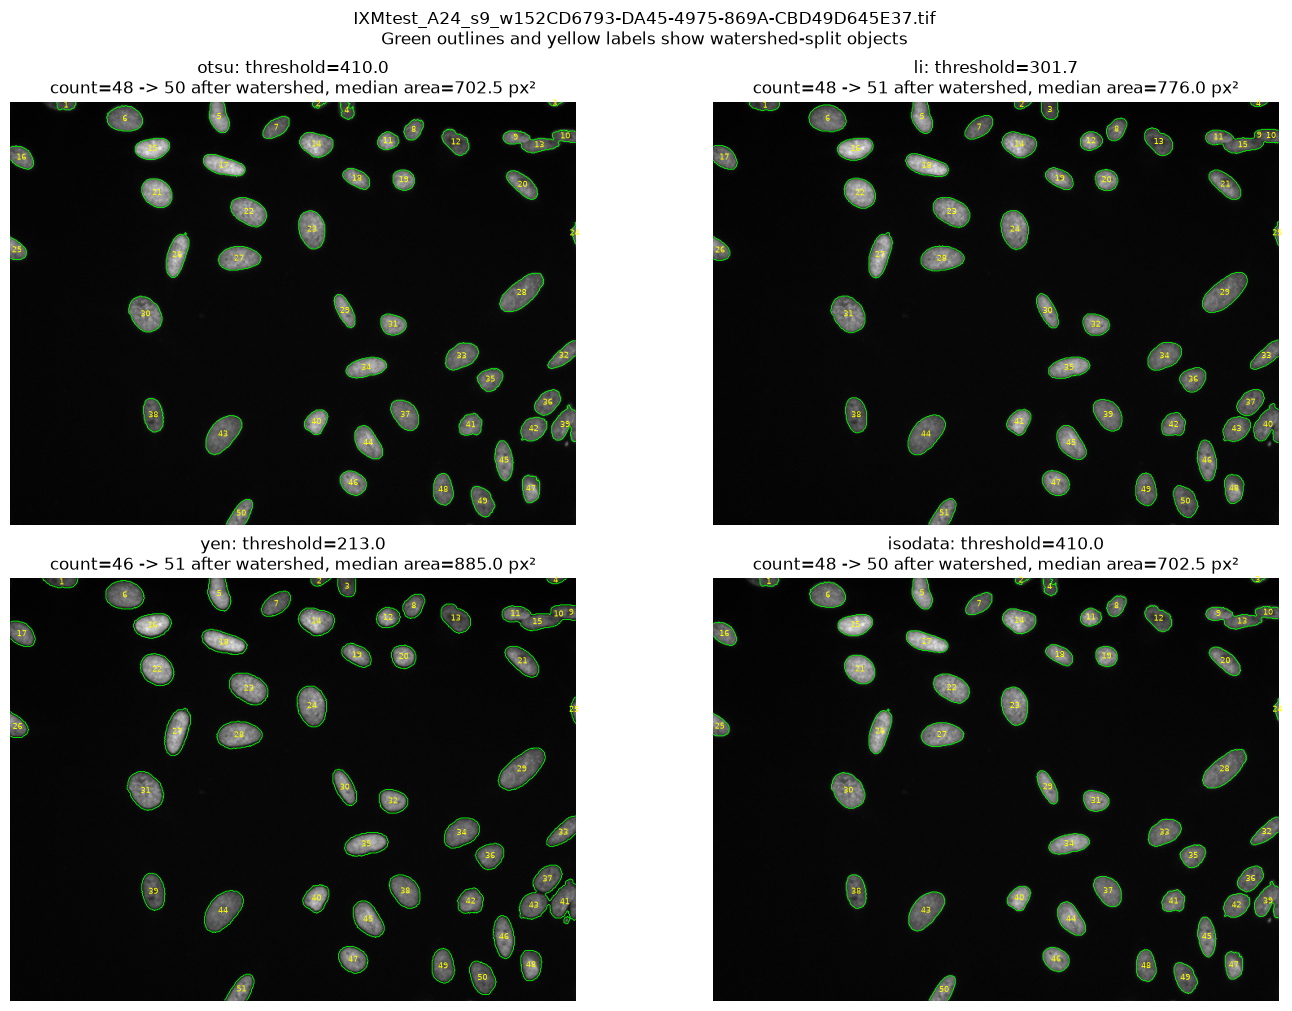

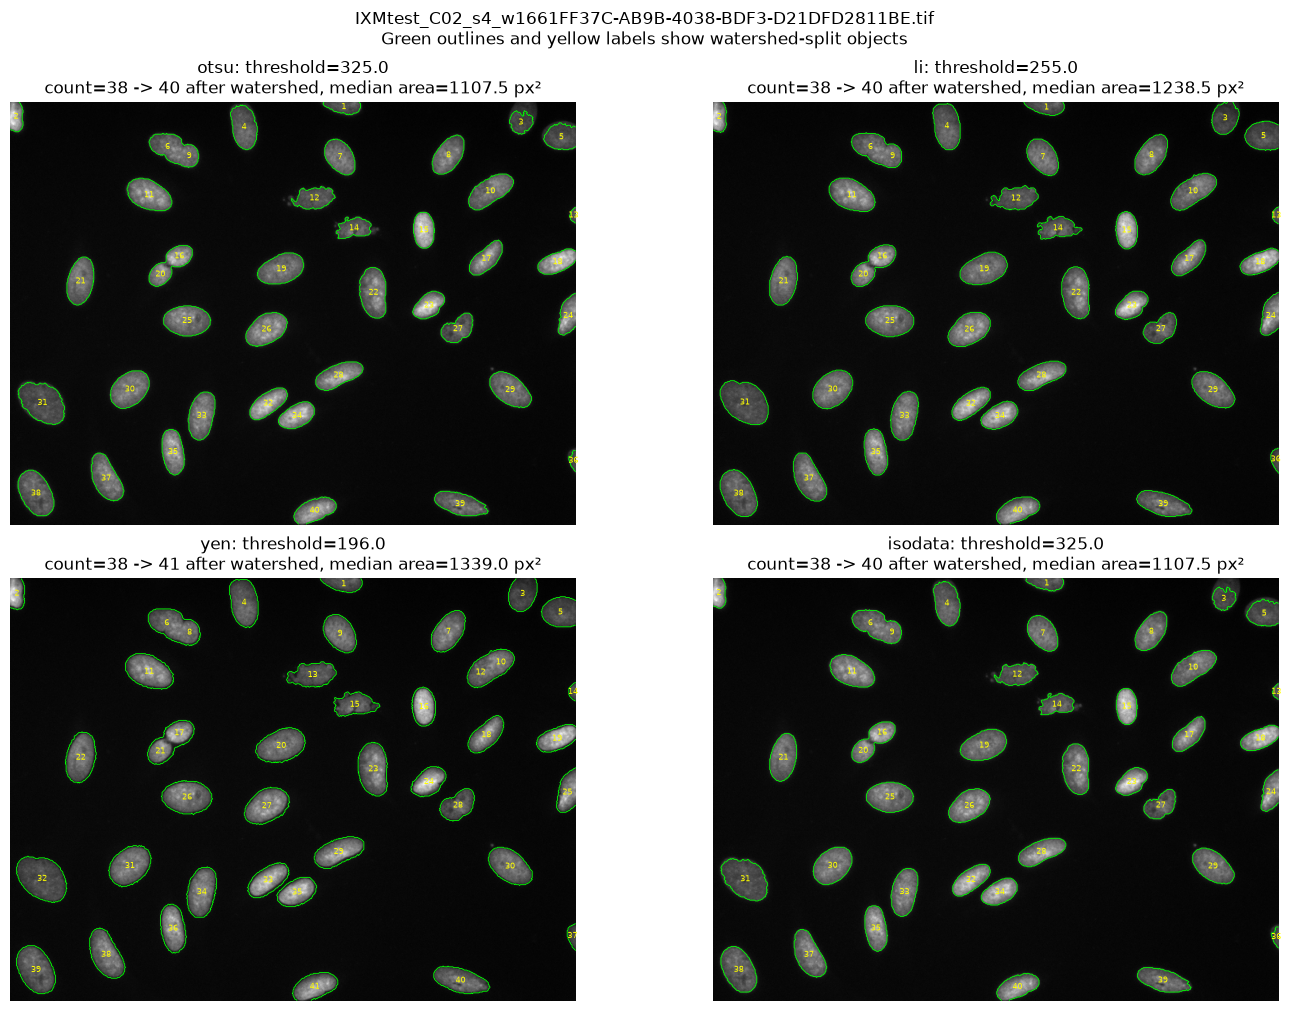

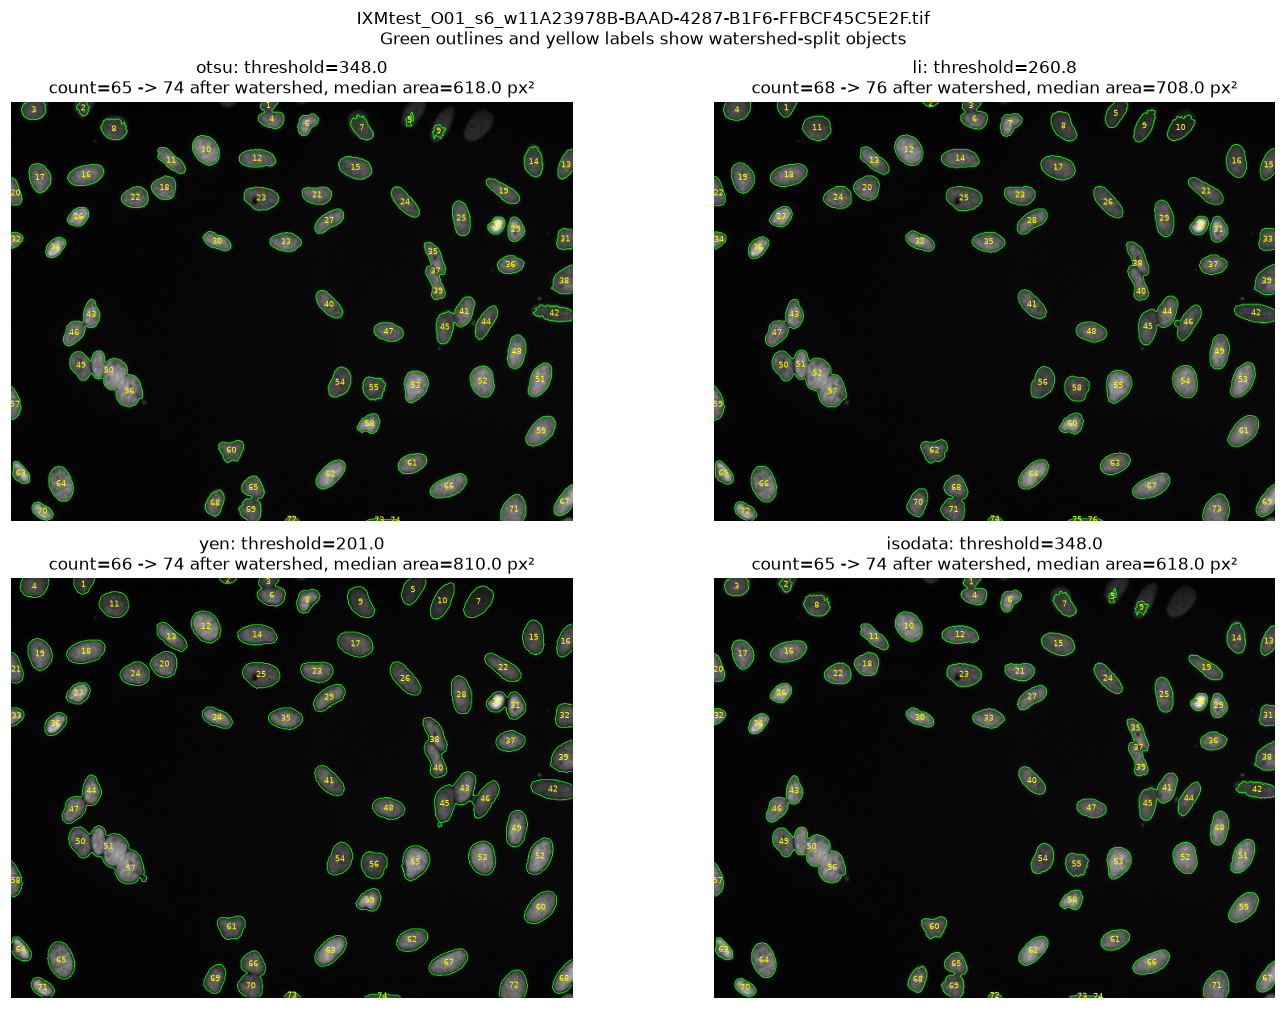

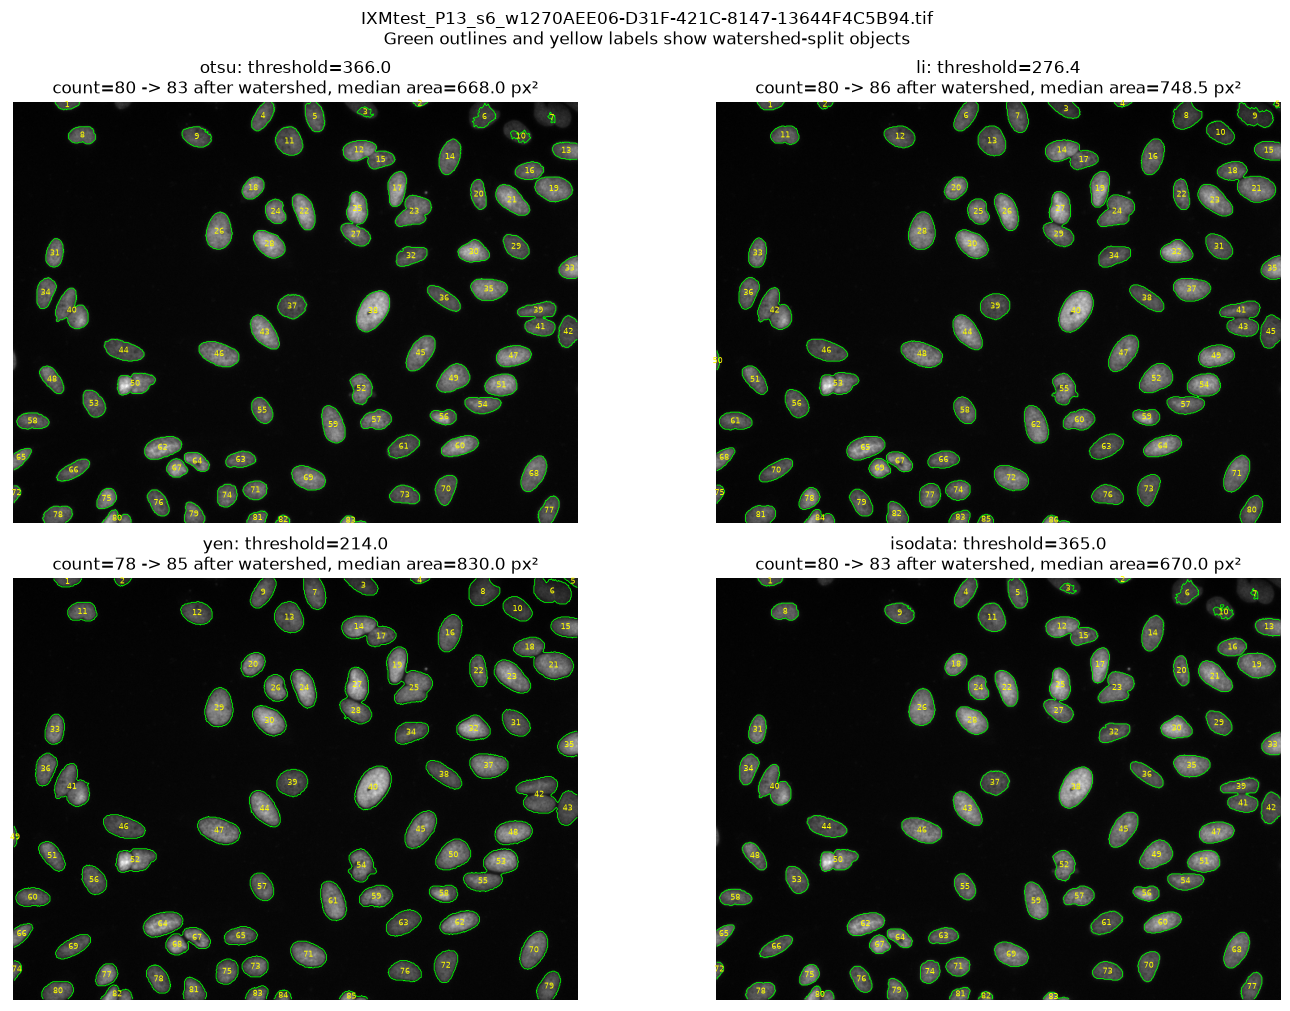

In [5]:
# short form of the thresholding methods for easier iteration
threshold_methods = {
    "otsu": threshold_otsu,
    "li": threshold_li,
    "yen": threshold_yen,
    "isodata": threshold_isodata,
}

# some parametres for the analysis
MIN_OBJECT_AREA = 50
MIN_HOLE_AREA = 50
CLOSING_RADIUS = 1
WATERSHED_MIN_DISTANCE = 14

def label_summary(labels):
    objects = measure.regionprops(labels)
    areas = np.array([obj.area for obj in objects], dtype=float)
    return len(objects), float(np.median(areas)) if areas.size else np.nan # ignore empty labels

def split_touching_objects(mask):
    distance = ndi.distance_transform_edt(mask)
    peak_coordinates = peak_local_max(
        distance,
        min_distance=WATERSHED_MIN_DISTANCE, # after testing, 14 to 15 px seems to work well for the nuclei in this dataset
        labels=mask,
        exclude_border=False,
    )
    peak_mask = np.zeros(mask.shape, dtype=bool)
    if peak_coordinates.size:
        peak_mask[tuple(peak_coordinates.T)] = True
    markers = measure.label(peak_mask)
    return watershed(-distance, markers, mask=mask)

def analyze_image(image, method_name, threshold_function):
    threshold_value = float(threshold_function(image))
    raw_mask = image > threshold_value
    cleaned_mask = closing(raw_mask, disk(CLOSING_RADIUS))
    cleaned_mask = remove_small_objects(cleaned_mask, max_size=MIN_OBJECT_AREA)
    cleaned_mask = remove_small_holes(cleaned_mask, max_size=MIN_HOLE_AREA)

    labels = measure.label(cleaned_mask)
    count, median_area = label_summary(labels)
    split_labels = split_touching_objects(cleaned_mask)
    split_count, split_median_area = label_summary(split_labels)
    return {
        "method": method_name,
        "threshold": threshold_value,
        "raw_foreground_pixels": int(raw_mask.sum()),
        "count": count,
        "median_object_area": median_area,
        "split_count": split_count,
        "split_median_object_area": split_median_area,
        "mask": cleaned_mask,
        "labels": labels,
        "split_labels": split_labels,
    }

results = []
for file in files:
    image = plt.imread(os.path.join(data_dir, file))
    image_results = [
        analyze_image(image, method_name, threshold_function)
        for method_name, threshold_function in threshold_methods.items()
    ]
    for result in image_results:
        results.append({
            "image": file,
            "method": result["method"],
            "threshold": result["threshold"],
            "min_object_area": MIN_OBJECT_AREA,
            "min_hole_area": MIN_HOLE_AREA,
            "closing_radius": CLOSING_RADIUS,
            "count": result["count"],
            "median_object_area": result["median_object_area"],
            "split_count": result["split_count"],
            "split_median_object_area": result["split_median_object_area"],
            "watershed_min_distance": WATERSHED_MIN_DISTANCE,
        })

summary = pd.DataFrame(results)
display(summary)
if not os.path.exists("../../output"):
    os.makedirs("../../output")
summary.to_csv("../../output/segmentation_summary.csv", index=False)

for file in files:
    image = plt.imread(os.path.join(data_dir, file))
    image_results = [
        analyze_image(image, method_name, threshold_function)
        for method_name, threshold_function in threshold_methods.items()
    ]
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    for ax, result in zip(axes.flat, image_results):
        ax.imshow(image, cmap="gray") # show images as grayscale (should be single-channel images anyway)
        ax.contour(result["split_labels"] > 0, levels=[0.5], colors="lime", linewidths=0.6) # green outlines for split objects
        for region in measure.regionprops(result["split_labels"]):
            y, x = region.centroid
            ax.text(x, y, str(region.label), color="yellow", fontsize=6,
                    ha="center", va="center")
        median_area = result["split_median_object_area"]
        median_text = f"{median_area:.1f}" if np.isfinite(median_area) else "n/a"
        ax.set_title(
            f"{result['method']}: threshold={result['threshold']:.1f}\n"
            f"count={result['count']} -> {result['split_count']} after watershed, "
            f"median area={median_text} px²"
        )
        ax.axis("off")
    fig.suptitle(
        f"{file}\nGreen outlines and yellow labels show watershed-split objects",
        fontsize=12,
    )
    fig.savefig(f"../../output/{file}_segmentation_results.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)